# Analyst Rating Changes — HW8 v0 Data Build

This notebook builds the **small, working HW8 v0** for the analyst-upgrades project. It deliberately stays with five companies; expanding to 50 firms belongs to the later final-project stage.

**Sample:** AAPL, MSFT, AMZN, JPM, NVDA; January 1, 2021 through the run date.

**Outputs**
- `data/raw/ratings_raw.csv` — raw Yahoo Finance analyst-rating history
- `data/raw/prices_raw.csv` — adjusted daily prices for the five stocks and SPY
- `data/raw/earnings_dates_raw.csv` — historical earnings dates returned by Yahoo Finance
- `data/processed/events.csv` — one row per qualifying upgrade/downgrade
- `data/processed/event_day_panel.csv` — one row per event × relative trading day (-3 to +3)

**Timing convention:** Yahoo rating timestamps are interpreted as UTC and converted to US Eastern time. A pre-market rating (before 9:30 a.m. ET) is assigned to that trading day; a rating at/after 9:30 a.m. ET is assigned to the next trading day. This avoids using a full daily return that partly occurred before an intraday recommendation. The timestamp is still a vendor timestamp, not independently verified publication time.

**Earnings control:** Each event is matched to the nearest reported earnings date for that ticker. `earnings_overlap` flags earnings within one trading day before or after the event trading date. Missing earnings-date coverage remains missing, not a false zero.

**Return model:** Market-adjusted abnormal return = stock daily return − SPY daily return. CARs are sums of daily abnormal returns. These are descriptive event-study measures, not causal effects.


In [1]:
# Install dependencies (run once in Colab)
!pip -q install yfinance pandas numpy

In [2]:
from pathlib import Path
from datetime import date, timedelta
import re
import time

import numpy as np
import pandas as pd
import yfinance as yf

TICKERS = ["AAPL", "MSFT", "AMZN", "JPM", "NVDA"]
BENCHMARK = "SPY"
START_DATE = "2021-01-01"

# Yahoo's history() end date is exclusive. Add one day to include today's data.
END_DATE = (date.today() + timedelta(days=1)).isoformat()

ROOT = Path(".")
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("yfinance version:", yf.__version__)
print("Sample:", TICKERS)
print("Dates:", START_DATE, "through", date.today().isoformat())

yfinance version: 0.2.66
Sample: ['AAPL', 'MSFT', 'AMZN', 'JPM', 'NVDA']
Dates: 2021-01-01 through 2026-11-12


## 1. Download analyst rating history

First we preserve the full raw response. Do not filter out initiations, reiterations, or price-target-related records at this stage; retaining the raw source lets us document exactly what Yahoo supplied.

In [3]:
rating_frames = []

for symbol in TICKERS:
    print(f"Downloading ratings: {symbol}")
    try:
        tkr = yf.Ticker(symbol)
        df = tkr.upgrades_downgrades.copy()

        if df is None or df.empty:
            print(f"  WARNING: no rating history returned for {symbol}")
            continue

        df = df.reset_index()
        # yfinance versions may name the date index differently.
        date_col = next((c for c in df.columns if str(c).lower() in
                         ["gradedate", "date", "index"]), df.columns[0])
        df = df.rename(columns={date_col: "grade_datetime"})
        df["ticker"] = symbol
        rating_frames.append(df)
        print(f"  {len(df):,} records")
        time.sleep(0.25)

    except Exception as exc:
        print(f"  ERROR for {symbol}: {type(exc).__name__}: {exc}")

if not rating_frames:
    raise RuntimeError("No rating records were downloaded. Check the yfinance connection/API response.")

ratings_raw = pd.concat(rating_frames, ignore_index=True, sort=False)
ratings_raw.to_csv(RAW_DIR / "ratings_raw.csv", index=False)

print("\nRaw rows:", len(ratings_raw))
print("Columns:", ratings_raw.columns.tolist())
display(ratings_raw.head(10))

  981 records
  955 records
  989 records
  452 records
  1,008 records

Raw rows: 4385
Columns: ['grade_datetime', 'Firm', 'ToGrade', 'FromGrade', 'Action', 'priceTargetAction', 'currentPriceTarget', 'priorPriceTarget', 'ticker']


,grade_datetime,Firm,ToGrade,FromGrade,Action,priceTargetAction,currentPriceTarget,priorPriceTarget,ticker
0,2026-11-11 13:02:36,China Renaissance,Buy,Hold,up,Announces,425.0,0.0,AAPL
1,2026-11-04 09:04:41,Bernstein,Buy,Buy,main,Raises,380.0,370.0,AAPL
2,2026-11-03 18:16:44,JP Morgan,Overweight,Overweight,main,Lowers,355.0,360.0,AAPL
3,2026-11-03 15:48:58,UBS,Neutral,Neutral,main,Raises,340.0,296.0,AAPL
4,2026-11-03 14:17:08,Argus Research,Buy,Buy,main,Raises,400.0,375.0,AAPL
5,2026-11-03 14:12:11,Barclays,Underweight,Underweight,main,Raises,261.0,245.0,AAPL
6,2026-11-03 14:09:11,TD Cowen,Buy,Buy,main,Lowers,390.0,400.0,AAPL
7,2026-11-03 13:59:23,DA Davidson,Neutral,Neutral,main,Raises,295.0,270.0,AAPL
8,2026-11-03 13:45:57,Keybanc,Underweight,Underweight,reit,Maintains,250.0,250.0,AAPL
9,2026-11-03 12:32:06,Rosenblatt,Neutral,Neutral,main,Maintains,303.0,303.0,AAPL


## 2. Download adjusted daily prices

We download each ticker separately to avoid version-dependent multi-index column behavior. With `auto_adjust=True`, the `Close` field is adjusted for splits and distributions.

In [4]:
price_frames = []

# Include a short buffer before the first event date for event-window calculations.
PRICE_START = (pd.Timestamp(START_DATE) - pd.Timedelta(days=10)).strftime("%Y-%m-%d")

for symbol in TICKERS + [BENCHMARK]:
    print(f"Downloading prices: {symbol}")
    hist = yf.Ticker(symbol).history(
        start=PRICE_START,
        end=END_DATE,
        interval="1d",
        auto_adjust=True
    )

    if hist is None or hist.empty:
        print(f"  WARNING: no prices returned for {symbol}")
        continue

    tmp = hist.reset_index()
    date_col = next((c for c in tmp.columns if str(c).lower() in ["date", "datetime"]), tmp.columns[0])
    tmp = tmp.rename(columns={date_col: "date", "Close": "adjusted_close"})
    tmp["date"] = pd.to_datetime(tmp["date"], utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize()
    tmp["ticker"] = symbol
    price_frames.append(tmp[["date", "ticker", "adjusted_close"]])
    print(f"  {len(tmp):,} daily prices")
    time.sleep(0.25)

if not price_frames:
    raise RuntimeError("No price data downloaded.")

prices_raw = pd.concat(price_frames, ignore_index=True)
prices_raw = prices_raw.drop_duplicates(["ticker", "date"]).sort_values(["ticker", "date"])
prices_raw.to_csv(RAW_DIR / "prices_raw.csv", index=False)

display(prices_raw.head())
print("Price date range:", prices_raw.date.min(), "to", prices_raw.date.max())

  1,480 daily prices
  1,480 daily prices
  1,480 daily prices
  1,480 daily prices
  1,480 daily prices
  1,480 daily prices


,date,ticker,adjusted_close
0,2020-12-22,AAPL,128.030426
1,2020-12-23,AAPL,127.137276
2,2020-12-24,AAPL,128.117767
3,2020-12-28,AAPL,132.699997
4,2020-12-29,AAPL,130.933090


Price date range: 2020-12-22 00:00:00 to 2026-11-12 00:00:00


## 2B. Download historical earnings announcement dates

We use Yahoo Finance's earnings-date history for the same five tickers. Keep the raw response, including EPS fields when supplied. Availability can differ by ticker, so missing coverage is recorded and is not silently treated as "no earnings overlap".

In [5]:
earnings_frames = []

for symbol in TICKERS:
    print(f"Downloading earnings dates: {symbol}")
    try:
        tkr = yf.Ticker(symbol)
        ed = tkr.get_earnings_dates(limit=100)

        if ed is None or ed.empty:
            print(f"  WARNING: no earnings dates returned for {symbol}")
            continue

        ed = ed.reset_index()
        date_col = next(
            (c for c in ed.columns if "earnings" in str(c).lower() or str(c).lower() in ["index", "date"]),
            ed.columns[0]
        )
        ed = ed.rename(columns={date_col: "earnings_datetime"})
        ed["ticker"] = symbol
        earnings_frames.append(ed)
        print(f"  {len(ed):,} earnings records")
        time.sleep(0.25)

    except Exception as exc:
        print(f"  ERROR for {symbol}: {type(exc).__name__}: {exc}")

if earnings_frames:
    earnings_raw = pd.concat(earnings_frames, ignore_index=True, sort=False)
else:
    earnings_raw = pd.DataFrame(columns=["earnings_datetime", "ticker"])

earnings_raw.to_csv(RAW_DIR / "earnings_dates_raw.csv", index=False)

print("\nRaw earnings-date records:", len(earnings_raw))
print("Tickers with earnings-date coverage:", earnings_raw["ticker"].nunique() if not earnings_raw.empty else 0)
display(earnings_raw.head(10))

  100 earnings records
  100 earnings records
  100 earnings records
  100 earnings records
  100 earnings records

Raw earnings-date records: 500
Tickers with earnings-date coverage: 5


,earnings_datetime,EPS Estimate,Reported EPS,Surprise(%),ticker
0,2027-01-28 16:00:00-05:00,2.91,NaN,NaN,AAPL
1,2026-11-02 16:00:00-05:00,1.98,2.10,5.80,AAPL
2,2026-07-30 16:00:00-04:00,1.89,2.02,6.74,AAPL
3,2026-04-30 16:00:00-04:00,1.94,2.01,3.46,AAPL
4,2026-01-29 16:00:00-05:00,2.67,2.84,6.25,AAPL
5,2025-10-30 16:00:00-04:00,1.77,1.85,4.52,AAPL
6,2025-07-31 16:00:00-04:00,1.43,1.57,9.48,AAPL
7,2025-05-01 16:00:00-04:00,1.62,1.65,1.69,AAPL
8,2025-01-30 16:00:00-05:00,2.35,2.40,2.26,AAPL
9,2024-10-31 16:00:00-04:00,0.95,0.97,2.48,AAPL


## 3. Clean rating changes and identify upgrades/downgrades

The raw data is retained above. For this first event sample, we classify an event using Yahoo's `Action` field and keep only explicit upgrade/up and downgrade/down actions. Initiations and reiterations are not treated as upgrades/downgrades.

We keep the original grade labels rather than trying to impose a universal numeric ranking across rating vocabularies.

In [6]:
# Normalize expected source columns while retaining the raw file unchanged.
required_source_cols = ["ticker", "grade_datetime", "Firm", "ToGrade", "FromGrade", "Action"]
missing = [c for c in required_source_cols if c not in ratings_raw.columns]
if missing:
    raise ValueError(
        f"Expected columns not found: {missing}. Actual columns: {ratings_raw.columns.tolist()}. "
        "Inspect ratings_raw and update the mapping before proceeding."
    )

ratings = ratings_raw.copy()

# Yahoo's rating timestamps are treated as UTC, then converted to US Eastern.
ratings["grade_datetime"] = pd.to_datetime(ratings["grade_datetime"], errors="coerce", utc=True)
ratings["event_datetime_et"] = ratings["grade_datetime"].dt.tz_convert("America/New_York")
ratings["event_date"] = (
    ratings["event_datetime_et"].dt.tz_localize(None).dt.normalize()
)
ratings["event_time_et"] = ratings["event_datetime_et"].dt.strftime("%H:%M:%S")

ratings["action_clean"] = ratings["Action"].astype(str).str.strip().str.lower()

def classify_action(action):
    if re.search(r"\b(up|upgrade|upgraded)\b", action):
        return "Upgrade"
    if re.search(r"\b(down|downgrade|downgraded)\b", action):
        return "Downgrade"
    return np.nan

ratings["event_type"] = ratings["action_clean"].apply(classify_action)

events = ratings.loc[ratings["event_type"].notna()].copy()
events = events.loc[events["event_date"] >= pd.Timestamp(START_DATE)].copy()

events = events.rename(columns={
    "Firm": "broker",
    "FromGrade": "from_grade",
    "ToGrade": "to_grade",
    "Action": "source_action"
})

events["broker"] = events["broker"].astype(str).str.strip()
events["from_grade"] = events["from_grade"].astype(str).str.strip()
events["to_grade"] = events["to_grade"].astype(str).str.strip()

key_cols = ["ticker", "event_date", "broker", "from_grade", "to_grade", "event_type"]
events["duplicate_n"] = events.groupby(key_cols, dropna=False).cumcount() + 1
events["event_id"] = (
    events["ticker"].astype(str) + "_" +
    events["event_date"].dt.strftime("%Y%m%d") + "_" +
    events["broker"].str.replace(r"[^A-Za-z0-9]+", "", regex=True) + "_" +
    events["duplicate_n"].astype(str)
)

events = events[[
    "event_id", "ticker", "event_date", "grade_datetime", "event_datetime_et",
    "event_time_et", "broker", "from_grade", "to_grade", "event_type",
    "source_action", "duplicate_n"
]].sort_values(["event_date", "ticker", "broker"]).reset_index(drop=True)

print("All raw rating records:", len(ratings_raw))
print("Qualifying upgrades/downgrades:", len(events))
print("Upgrades:", (events.event_type == "Upgrade").sum())
print("Downgrades:", (events.event_type == "Downgrade").sum())
print("Tickers represented:", events.ticker.nunique())
display(events.head(15))

All raw rating records: 4385
Qualifying upgrades/downgrades: 138
Upgrades: 70
Downgrades: 68
Tickers represented: 5


,event_id,ticker,event_date,grade_datetime,event_datetime_et,event_time_et,broker,from_grade,to_grade,event_type,source_action,duplicate_n
0,JPM_20210107_BofASecurities_1,JPM,2021-01-07,2021-01-07 12:45:59+00:00,2021-01-07 07:45:59-05:00,07:45:59,B of A Securities,Neutral,Buy,Upgrade,up,1
1,JPM_20210107_Jefferies_1,JPM,2021-01-07,2021-01-07 10:16:30+00:00,2021-01-07 05:16:30-05:00,05:16:30,Jefferies,Hold,Buy,Upgrade,up,1
2,AAPL_20210331_UBS_1,AAPL,2021-03-31,2021-03-31 10:26:27+00:00,2021-03-31 06:26:27-04:00,06:26:27,UBS,Neutral,Buy,Upgrade,up,1
3,NVDA_20210415_RaymondJames_1,NVDA,2021-04-15,2021-04-15 11:24:42+00:00,2021-04-15 07:24:42-04:00,07:24:42,Raymond James,Outperform,Strong Buy,Upgrade,up,1
4,JPM_20210427_AtlanticEquities_1,JPM,2021-04-27,2021-04-27 10:19:32+00:00,2021-04-27 06:19:32-04:00,06:19:32,Atlantic Equities,Overweight,Neutral,Downgrade,down,1
5,AAPL_20210429_GoldmanSachs_1,AAPL,2021-04-29,2021-04-29 10:19:33+00:00,2021-04-29 06:19:33-04:00,06:19:33,Goldman Sachs,Sell,Neutral,Upgrade,up,1
6,NVDA_20210527_CraigHallum_1,NVDA,2021-05-27,2021-05-27 12:48:41+00:00,2021-05-27 08:48:41-04:00,08:48:41,Craig-Hallum,Hold,Buy,Upgrade,up,1
7,AAPL_20210528_NewStreetResearch_1,AAPL,2021-05-28,2021-05-28 11:21:08+00:00,2021-05-28 07:21:08-04:00,07:21:08,New Street Research,Neutral,Sell,Downgrade,down,1
8,NVDA_20210819_SummitInsightsGroup_1,NVDA,2021-08-19,2021-08-19 10:38:11+00:00,2021-08-19 06:38:11-04:00,06:38:11,Summit Insights Group,Hold,Sell,Downgrade,down,1
9,AAPL_20210901_WolfeResearch_1,AAPL,2021-09-01,2021-09-01 13:04:22+00:00,2021-09-01 09:04:22-04:00,09:04:22,Wolfe Research,Underperform,Peer Perform,Upgrade,up,1


## 3B. Assign the event trading day and match earnings announcements

**Event-day convention**
- Before 9:30 a.m. ET: same trading day, if the market is open.
- 9:30 a.m. ET or later: next trading day.
- Weekends and market holidays: use the next available trading session after the target date.

For earnings, calculate the signed distance in trading sessions between the nearest earnings date and the assigned event trading day. `earnings_overlap` is true when the absolute distance is one trading day or less. If Yahoo returns no earnings dates for a ticker, the overlap indicator stays missing.

In [12]:

# ============================================================
# CELL 12: EARNINGS MATCHING + EVENT TRADING-DATE ASSIGNMENT
# ============================================================

# 0. Make the cell safe to rerun
# Remove duplicate column names and previously calculated fields.

events = events.loc[:, ~events.columns.duplicated()].copy()

derived_columns = [
    "event_trade_date",
    "nearest_earnings_date",
    "days_from_earnings",
    "earnings_overlap",
    "earnings_data_available"
]

events = events.drop(
    columns=derived_columns,
    errors="ignore"
)


# ------------------------------------------------------------
# 1. Build trading calendars
# ------------------------------------------------------------

trading_dates = {
    ticker: pd.DatetimeIndex(
        prices_raw.loc[
            prices_raw.ticker == ticker, "date"
        ].dropna().sort_values().unique()
    )
    for ticker in TICKERS
}


# ------------------------------------------------------------
# 2. Timestamp conversion and trading-session assignment
# ------------------------------------------------------------

def eastern_timestamp(value):
    """Convert timestamp to US Eastern time."""

    ts = pd.Timestamp(value)

    if ts.tzinfo is None:
        ts = ts.tz_localize("America/New_York")
    else:
        ts = ts.tz_convert("America/New_York")

    return ts


def assign_announcement_session(timestamp, ticker):
    """
    Assign announcement to the appropriate trading session.

    Before 9:30 AM ET: same trading day.
    At/after 9:30 AM ET: next trading day.
    Weekends and holidays: next available trading session.
    """

    ts = eastern_timestamp(timestamp)

    target_date = (
        ts.tz_localize(None).normalize()
    )

    if ts.time() >= pd.Timestamp("09:30:00").time():
        target_date += pd.Timedelta(days=1)

    dates = trading_dates.get(
        ticker, pd.DatetimeIndex([])
    )

    pos = dates.searchsorted(
        target_date, side="left"
    )

    if pos >= len(dates):
        return pd.NaT

    return dates[pos]


# ------------------------------------------------------------
# 3. Clean historical earnings announcements
# ------------------------------------------------------------

if not earnings_raw.empty:

    earnings = earnings_raw.copy()

    # Locate reported EPS column.
    reported_eps_col = next(
        (
            c for c in earnings.columns
            if str(c).strip().lower()
            in ["reported eps", "reported_eps"]
        ),
        None
    )

    if reported_eps_col is None:

        print("WARNING: Reported EPS column unavailable.")

        earnings = pd.DataFrame(
            columns=[
                "ticker",
                "earnings_datetime",
                "earnings_trade_date"
            ]
        )

    else:

        # Keep only announcements with reported EPS.
        # This excludes future estimates.
        earnings = earnings.loc[
            earnings[reported_eps_col].notna()
        ].copy()

        # Preserve original timestamps in UTC.
        earnings["earnings_datetime"] = pd.to_datetime(
            earnings["earnings_datetime"],
            errors="coerce",
            utc=True
        )

        # Assign announcements to trading sessions.
        earnings["earnings_trade_date"] = earnings.apply(
            lambda row: assign_announcement_session(
                row["earnings_datetime"],
                row["ticker"]
            ),
            axis=1
        )

        earnings = earnings.dropna(
            subset=["earnings_trade_date"]
        )

        earnings = earnings[
            [
                "ticker",
                "earnings_datetime",
                "earnings_trade_date"
            ]
        ].drop_duplicates()

else:

    earnings = pd.DataFrame(
        columns=[
            "ticker",
            "earnings_datetime",
            "earnings_trade_date"
        ]
    )


# Save cleaned earnings dataset.
earnings.to_csv(
    PROCESSED_DIR / "earnings_dates.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Build earnings calendars by ticker
# ------------------------------------------------------------

earnings_trading_dates = {}
earnings_coverage = {}

for ticker in TICKERS:

    ticker_earnings = earnings.loc[
        earnings.ticker == ticker,
        "earnings_trade_date"
    ].dropna()

    earnings_trading_dates[ticker] = pd.DatetimeIndex(
        sorted(ticker_earnings.unique())
    )

    earnings_coverage[ticker] = (
        len(earnings_trading_dates[ticker]) > 0
    )


print("Historical earnings coverage:")

for ticker in TICKERS:
    print(
        ticker,
        len(earnings_trading_dates[ticker]),
        "announcements"
    )


# ------------------------------------------------------------
# 5. Assign analyst rating changes to trading sessions
# ------------------------------------------------------------

events["event_trade_date"] = events.apply(
    lambda row: assign_announcement_session(
        row["event_datetime_et"],
        row["ticker"]
    ),
    axis=1
)


# ------------------------------------------------------------
# 6. Match each rating change to nearest earnings date
# ------------------------------------------------------------

def nearest_earnings_match(row):

    ticker = row.ticker

    dates = trading_dates.get(
        ticker, pd.DatetimeIndex([])
    )

    earnings_dates = earnings_trading_dates.get(
        ticker, pd.DatetimeIndex([])
    )

    has_coverage = earnings_coverage.get(
        ticker, False
    )

    # Separate earnings-data availability from
    # whether an event has an assigned trading date.

    if (
        pd.isna(row.event_trade_date)
        or len(earnings_dates) == 0
        or len(dates) == 0
    ):

        return pd.Series({
            "nearest_earnings_date": pd.NaT,
            "days_from_earnings": np.nan,
            "earnings_overlap": pd.NA,
            "earnings_data_available": has_coverage
        })

    event_pos = dates.get_indexer(
        [pd.Timestamp(row.event_trade_date)]
    )[0]

    candidates = []

    for earnings_date in earnings_dates:

        earnings_pos = dates.get_indexer(
            [pd.Timestamp(earnings_date)]
        )[0]

        if earnings_pos >= 0:

            # Positive = rating change AFTER earnings.
            # Negative = rating change BEFORE earnings.

            distance = event_pos - earnings_pos

            candidates.append((
                abs(distance),
                distance,
                earnings_date
            ))

    if not candidates:

        return pd.Series({
            "nearest_earnings_date": pd.NaT,
            "days_from_earnings": np.nan,
            "earnings_overlap": pd.NA,
            "earnings_data_available": has_coverage
        })

    _, signed_distance, nearest_date = min(
        candidates,
        key=lambda x: (x[0], x[2])
    )

    return pd.Series({
        "nearest_earnings_date": nearest_date,
        "days_from_earnings": signed_distance,
        "earnings_overlap": abs(signed_distance) <= 1,
        "earnings_data_available": has_coverage
    })


# Calculate earnings matches.
earnings_matches = events.apply(
    nearest_earnings_match,
    axis=1
)

# Attach exactly one copy of each calculated column.
events = pd.concat(
    [events, earnings_matches],
    axis=1
)

events["earnings_overlap"] = (
    events["earnings_overlap"].astype("boolean")
)


# ------------------------------------------------------------
# 7. Review results
# ------------------------------------------------------------

print("\nEvent trading-date coverage:")

print(
    events["event_trade_date"].notna().sum(),
    "/",
    len(events)
)


print("\nEarnings-data coverage:")

print(
    events["earnings_data_available"].sum(),
    "/",
    len(events)
)


print("\nEarnings overlap:")

covered_events = events.loc[
    events["earnings_data_available"] == True
]

print(
    covered_events["earnings_overlap"]
    .value_counts(dropna=False)
)


print("\nEvents by ticker:")

display(
    events.groupby("ticker").agg(
        total_events=("event_id", "count"),
        earnings_coverage=(
            "earnings_data_available", "sum"
        ),
        earnings_overlaps=(
            "earnings_overlap",
            lambda x: int(x.fillna(False).sum())
        )
    )
)


print("\nSample event matches:")

display(
    events[[
        "ticker",
        "event_date",
        "event_time_et",
        "event_trade_date",
        "nearest_earnings_date",
        "days_from_earnings",
        "earnings_overlap",
        "earnings_data_available"
    ]].head(20)
)

Historical earnings coverage:
AAPL 25 announcements
MSFT 25 announcements
AMZN 25 announcements
JPM 25 announcements
NVDA 24 announcements

Event trading-date coverage:
135 / 138

Earnings-data coverage:
138 / 138

Earnings overlap:
earnings_overlap
False    106
True      29
<NA>       3
Name: count, dtype: Int64

Events by ticker:


,total_events,earnings_coverage,earnings_overlaps
ticker,,,
AAPL,55,55,8
AMZN,7,7,3
JPM,19,19,1
MSFT,19,19,5
NVDA,38,38,12



Sample event matches:


,ticker,event_date,event_time_et,event_trade_date,nearest_earnings_date,days_from_earnings,earnings_overlap,earnings_data_available
0,JPM,2021-01-07,07:45:59,2021-01-07,2021-01-15,-6.0,False,True
1,JPM,2021-01-07,05:16:30,2021-01-07,2021-01-15,-6.0,False,True
2,AAPL,2021-03-31,06:26:27,2021-03-31,2021-04-29,-20.0,False,True
3,NVDA,2021-04-15,07:24:42,2021-04-15,2021-05-27,-30.0,False,True
4,JPM,2021-04-27,06:19:32,2021-04-27,2021-04-14,9.0,False,True
5,AAPL,2021-04-29,06:19:33,2021-04-29,2021-04-29,0.0,True,True
6,NVDA,2021-05-27,08:48:41,2021-05-27,2021-05-27,0.0,True,True
7,AAPL,2021-05-28,07:21:08,2021-05-28,2021-04-29,21.0,False,True
8,NVDA,2021-08-19,06:38:11,2021-08-19,2021-08-19,0.0,True,True
9,AAPL,2021-09-01,09:04:22,2021-09-01,2021-07-28,25.0,False,True


## 4. Calculate daily returns and build the event-day panel

The panel has one row per **rating event × relative trading day**. Relative day 0 is the first trading date on or after Yahoo's event calendar date. This is a provisional timing convention, not proof that the market could trade on the recommendation that day.

In [13]:
# Daily returns for each stock and SPY.
prices = prices_raw.copy()
prices = prices.sort_values(["ticker", "date"])
prices["daily_return"] = prices.groupby("ticker")["adjusted_close"].pct_change()

spy = (
    prices.loc[prices.ticker == BENCHMARK, ["date", "daily_return"]]
    .rename(columns={"daily_return": "market_return"})
    .dropna()
)

stock_returns = prices.loc[prices.ticker.isin(TICKERS), ["ticker", "date", "daily_return"]].copy()
returns = stock_returns.merge(spy, on="date", how="left", validate="many_to_one")
returns["abnormal_return"] = returns["daily_return"] - returns["market_return"]

trading_dates = {
    ticker: pd.DatetimeIndex(
        returns.loc[returns.ticker == ticker, "date"].dropna().sort_values().unique()
    )
    for ticker in TICKERS
}

panel_rows = []
unmatched_events = []

for row in events.itertuples(index=False):
    dates = trading_dates.get(row.ticker, pd.DatetimeIndex([]))
    if len(dates) == 0 or pd.isna(row.event_trade_date):
        unmatched_events.append((row.event_id, "no assigned event trading date"))
        continue

    event_pos = dates.get_indexer([pd.Timestamp(row.event_trade_date)])[0]
    if event_pos < 0:
        unmatched_events.append((row.event_id, "event trading date absent from price calendar"))
        continue

    for rel_day in range(-3, 4):
        p = event_pos + rel_day
        if p < 0 or p >= len(dates):
            continue

        obs_date = dates[p]
        match = returns.loc[
            (returns.ticker == row.ticker) & (returns.date == obs_date)
        ]
        if match.empty:
            continue

        m = match.iloc[0]
        panel_rows.append({
            "event_id": row.event_id,
            "ticker": row.ticker,
            "broker": row.broker,
            "event_date": row.event_date,
            "event_datetime_et": row.event_datetime_et,
            "event_trade_date": row.event_trade_date,
            "event_type": row.event_type,
            "from_grade": row.from_grade,
            "to_grade": row.to_grade,
            "nearest_earnings_date": row.nearest_earnings_date,
            "days_from_earnings": row.days_from_earnings,
            "earnings_overlap": row.earnings_overlap,
            "relative_day": rel_day,
            "observation_date": obs_date,
            "stock_return": m["daily_return"],
            "market_return": m["market_return"],
            "abnormal_return": m["abnormal_return"]
        })

event_day_panel = pd.DataFrame(panel_rows)
if event_day_panel.empty:
    raise RuntimeError("The event-day panel is empty. Check event timing and price downloads.")

event_day_panel.to_csv(PROCESSED_DIR / "event_day_panel.csv", index=False)

print("Event-day panel rows:", len(event_day_panel))
print("Events represented:", event_day_panel.event_id.nunique())
print("Unmatched events:", len(unmatched_events))
display(event_day_panel.head(14))

Event-day panel rows: 926
Events represented: 135
Unmatched events: 3


,event_id,ticker,broker,event_date,event_datetime_et,event_trade_date,event_type,from_grade,to_grade,nearest_earnings_date,days_from_earnings,earnings_overlap,relative_day,observation_date,stock_return,market_return,abnormal_return
0,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,-3,2021-01-04,-0.009444,-0.013614,0.004170
1,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,-2,2021-01-05,0.005441,0.006887,-0.001446
2,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,-1,2021-01-06,0.046956,0.005978,0.040978
3,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,0,2021-01-07,0.032839,0.014858,0.017981
4,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,1,2021-01-08,0.001104,0.005698,-0.004594
5,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,2,2021-01-11,0.014924,-0.006741,0.021665
6,JPM_20210107_BofASecurities_1,JPM,B of A Securities,2021-01-07,2021-01-07 07:45:59-05:00,2021-01-07,Upgrade,Neutral,Buy,2021-01-15,-6.0,False,3,2021-01-12,0.015719,0.000211,0.015508
7,JPM_20210107_Jefferies_1,JPM,Jefferies,2021-01-07,2021-01-07 05:16:30-05:00,2021-01-07,Upgrade,Hold,Buy,2021-01-15,-6.0,False,-3,2021-01-04,-0.009444,-0.013614,0.004170
8,JPM_20210107_Jefferies_1,JPM,Jefferies,2021-01-07,2021-01-07 05:16:30-05:00,2021-01-07,Upgrade,Hold,Buy,2021-01-15,-6.0,False,-2,2021-01-05,0.005441,0.006887,-0.001446
9,JPM_20210107_Jefferies_1,JPM,Jefferies,2021-01-07,2021-01-07 05:16:30-05:00,2021-01-07,Upgrade,Hold,Buy,2021-01-15,-6.0,False,-1,2021-01-06,0.046956,0.005978,0.040978


## 5. Create the event-level dataset and initial CAR measures

For each event, calculate CARs over [-1,+1] and [0,+1]. We require every trading-day observation in the requested window; incomplete windows are left missing rather than silently summing partial windows.

In [14]:
def window_car(group, start_day, end_day):
    window = group.loc[
        group.relative_day.between(start_day, end_day)
    ].sort_values("relative_day")

    expected_n = end_day - start_day + 1
    if len(window) != expected_n or window["abnormal_return"].isna().any():
        return np.nan
    return window["abnormal_return"].sum()

car_records = []
for event_id, group in event_day_panel.groupby("event_id"):
    car_records.append({
        "event_id": event_id,
        "AR_0": window_car(group, 0, 0),
        "CAR_m1_p1": window_car(group, -1, 1),
        "CAR_0_p1": window_car(group, 0, 1)
    })

cars = pd.DataFrame(car_records)
events = events.drop(columns=["AR_0", "CAR_m1_p1", "CAR_0_p1"], errors="ignore")
events = events.merge(cars, on="event_id", how="left", validate="one_to_one")

events.to_csv(PROCESSED_DIR / "events.csv", index=False)

print("Event-level rows:", len(events))
print("Unique events:", events.event_id.nunique())
print("Missing CAR[-1,+1]:", events.CAR_m1_p1.isna().sum())
display(events.head(15))

Event-level rows: 138
Unique events: 138
Missing CAR[-1,+1]: 8


,event_id,ticker,event_date,grade_datetime,event_datetime_et,event_time_et,broker,from_grade,to_grade,event_type,source_action,duplicate_n,event_trade_date,nearest_earnings_date,days_from_earnings,earnings_overlap,earnings_data_available,AR_0,CAR_m1_p1,CAR_0_p1
0,JPM_20210107_BofASecurities_1,JPM,2021-01-07,2021-01-07 12:45:59+00:00,2021-01-07 07:45:59-05:00,07:45:59,B of A Securities,Neutral,Buy,Upgrade,up,1,2021-01-07,2021-01-15,-6.0,False,True,0.017981,0.054365,0.013388
1,JPM_20210107_Jefferies_1,JPM,2021-01-07,2021-01-07 10:16:30+00:00,2021-01-07 05:16:30-05:00,05:16:30,Jefferies,Hold,Buy,Upgrade,up,1,2021-01-07,2021-01-15,-6.0,False,True,0.017981,0.054365,0.013388
2,AAPL_20210331_UBS_1,AAPL,2021-03-31,2021-03-31 10:26:27+00:00,2021-03-31 06:26:27-04:00,06:26:27,UBS,Neutral,Buy,Upgrade,up,1,2021-03-31,2021-04-29,-20.0,False,True,0.014712,0.001250,0.010872
3,NVDA_20210415_RaymondJames_1,NVDA,2021-04-15,2021-04-15 11:24:42+00:00,2021-04-15 07:24:42-04:00,07:24:42,Raymond James,Outperform,Strong Buy,Upgrade,up,1,2021-04-15,2021-05-27,-30.0,False,True,0.045568,0.006042,0.028298
4,JPM_20210427_AtlanticEquities_1,JPM,2021-04-27,2021-04-27 10:19:32+00:00,2021-04-27 06:19:32-04:00,06:19:32,Atlantic Equities,Overweight,Neutral,Downgrade,down,1,2021-04-27,2021-04-14,9.0,False,True,0.004799,0.011941,0.011565
5,AAPL_20210429_GoldmanSachs_1,AAPL,2021-04-29,2021-04-29 10:19:33+00:00,2021-04-29 06:19:33-04:00,06:19:33,Goldman Sachs,Sell,Neutral,Upgrade,up,1,2021-04-29,2021-04-29,0.0,True,True,-0.007122,-0.021424,-0.015684
6,NVDA_20210527_CraigHallum_1,NVDA,2021-05-27,2021-05-27 12:48:41+00:00,2021-05-27 08:48:41-04:00,08:48:41,Craig-Hallum,Hold,Buy,Upgrade,up,1,2021-05-27,2021-05-27,0.0,True,True,-0.014028,0.034382,0.033027
7,AAPL_20210528_NewStreetResearch_1,AAPL,2021-05-28,2021-05-28 11:21:08+00:00,2021-05-28 07:21:08-04:00,07:21:08,New Street Research,Neutral,Sell,Downgrade,down,1,2021-05-28,2021-04-29,21.0,False,True,-0.007136,-0.021806,-0.008904
8,NVDA_20210819_SummitInsightsGroup_1,NVDA,2021-08-19,2021-08-19 10:38:11+00:00,2021-08-19 06:38:11-04:00,06:38:11,Summit Insights Group,Hold,Sell,Downgrade,down,1,2021-08-19,2021-08-19,0.0,True,True,0.038262,0.071188,0.081724
9,AAPL_20210901_WolfeResearch_1,AAPL,2021-09-01,2021-09-01 13:04:22+00:00,2021-09-01 09:04:22-04:00,09:04:22,Wolfe Research,Underperform,Peer Perform,Upgrade,up,1,2021-09-01,2021-07-28,25.0,False,True,0.003947,0.001403,0.008346


## 6. Basic data checks and summary outputs

These are checks, not proof that the dataset is complete or unbiased. Review warnings and inspect sample rows before using the results in the proposal.

In [15]:
# Core integrity checks
assert events["event_id"].is_unique, "event_id must be unique in the event-level file"
assert set(events["event_type"].dropna().unique()).issubset({"Upgrade", "Downgrade"})
assert event_day_panel["relative_day"].between(-3, 3).all()
mapped_event_ids = set(events.loc[events["event_trade_date"].notna(), "event_id"])
assert event_day_panel["event_id"].nunique() == len(mapped_event_ids)

print("Event date range:", events.event_date.min(), "to", events.event_date.max())
print("Events assigned to a trading date:", events.event_trade_date.notna().sum(), "/", len(events))
print("Assigned event trading-date range:", events.event_trade_date.min(), "to", events.event_trade_date.max())

print("\\nEvents by ticker:")
display(events.groupby("ticker").size().rename("n_events").to_frame())

print("\\nEvents by type:")
display(events.groupby("event_type").size().rename("n_events").to_frame())

print("\\nEvents awaiting a future trading session:", events.event_trade_date.isna().sum())
print("\\nEarnings overlap coverage:")
display(events.groupby("ticker").agg(
    n_events=("event_id", "count"),
    earnings_dates_available=("earnings_data_available", "sum"),
    earnings_overlap_events=("earnings_overlap", lambda x: int(x.fillna(False).sum()))
))

print("\\nEvents by earnings overlap:")
display(events.groupby("earnings_overlap", dropna=False).agg(
    n_events=("event_id", "count"),
    mean_AR_0=("AR_0", "mean"),
    mean_CAR_m1_p1=("CAR_m1_p1", "mean")
))

print("\\nBroker coverage (top 20):")
display(events.groupby("broker").agg(
    n_events=("event_id", "count"),
    avg_AR_0=("AR_0", "mean"),
    avg_CAR_m1_p1=("CAR_m1_p1", "mean"),
    median_CAR_m1_p1=("CAR_m1_p1", "median")
).sort_values("n_events", ascending=False).head(20))

print("\\nMissingness:")
display(events[["AR_0", "CAR_m1_p1", "CAR_0_p1", "earnings_overlap"]].isna().mean().rename("missing_share").to_frame())

print("\\nSaved files:")
for path in [RAW_DIR / "ratings_raw.csv", RAW_DIR / "prices_raw.csv",
             RAW_DIR / "earnings_dates_raw.csv", PROCESSED_DIR / "earnings_dates.csv",
             PROCESSED_DIR / "events.csv", PROCESSED_DIR / "event_day_panel.csv"]:
    print(path, f"({path.stat().st_size:,} bytes)" if path.exists() else "MISSING")

Event date range: 2021-01-07 00:00:00 to 2026-11-12 00:00:00
Events assigned to a trading date: 135 / 138
Assigned event trading-date range: 2021-01-07 00:00:00 to 2026-11-12 00:00:00
\nEvents by ticker:


,n_events
ticker,
AAPL,55
AMZN,7
JPM,19
MSFT,19
NVDA,38


\nEvents by type:


,n_events
event_type,
Downgrade,68
Upgrade,70


\nEvents awaiting a future trading session: 3
\nEarnings overlap coverage:


,n_events,earnings_dates_available,earnings_overlap_events
ticker,,,
AAPL,55,55,8
AMZN,7,7,3
JPM,19,19,1
MSFT,19,19,5
NVDA,38,38,12


... (3 outputs left out)

,n_events,avg_AR_0,avg_CAR_m1_p1,median_CAR_m1_p1
broker,,,,
Jefferies,10,-0.002440,-0.004241,0.000929
DA Davidson,7,0.002949,-0.001535,-0.010871
Keybanc,7,-0.000250,0.019314,0.024623
Exane BNP Paribas,6,0.001105,0.016116,0.004866
Oppenheimer,5,0.001023,0.014984,0.018141
Loop Capital,5,0.004697,-0.000980,-0.007735
Rosenblatt,5,-0.003594,-0.020531,-0.073935
New Street Research,5,-0.002109,0.013071,0.022222
HSBC,4,-0.006731,0.006319,0.008293


\nMissingness:


,missing_share
AR_0,0.021739
CAR_m1_p1,0.057971
CAR_0_p1,0.057971
earnings_overlap,0.021739


\nSaved files:
data/raw/ratings_raw.csv (328,704 bytes)
data/raw/prices_raw.csv (300,663 bytes)
data/raw/earnings_dates_raw.csv (22,767 bytes)
data/processed/earnings_dates.csv (18,804 bytes)
data/processed/events.csv (34,098 bytes)
data/processed/event_day_panel.csv (201,150 bytes)


## 7. Manual validation checklist

Before treating this as the v0 dataset:

1. Open `data/raw/ratings_raw.csv` and compare a few records with Yahoo Finance's displayed rating history.
2. Pick at least three events and verify the stock and SPY returns against the downloaded price rows.
3. Check whether an event on a trading date should be assigned to that date or the next trading date. We do not know the publication time from a date alone.
4. Review the `Action` values that were excluded. Confirm the classification keeps upgrades/downgrades and excludes initiations/reiterations.
5. Check for missing tickers, brokers, grades, and dates.
6. Record the yfinance version, run date, and any errors in the project's `specs_tried.md`.

**Do not interpret the broker ranking yet.** Five companies are a pipeline test sample, not a representative universe. Broker sample sizes will be small and potentially highly uneven.


## 8. Interpretation and validation notes for HW8

- The sample remains **five firms**. Do not expand the universe for HW8 v0.
- `event_datetime_et` is the vendor timestamp converted from UTC to Eastern time. It is not independently verified as the exact moment the recommendation became public.
- The pre-market / intraday / after-close timing rule is a conservative convention using daily data. Intraday price data would be needed to measure the exact reaction to intraday calls.
- Yahoo earnings-date history may be incomplete or unavailable for some tickers. The processed earnings file keeps only dates with a non-missing `Reported EPS` value, excluding upcoming estimates. Report coverage explicitly. A missing earnings match is not classified as a clean, non-earnings event.
- Events for the same ticker on the same date can share identical stock returns. These are not independent stock-return observations; the final inference should account for ticker-date clustering or aggregate simultaneous calls for some analyses.
- The five-firm sample and broker counts are too small for strong broker-skill conclusions. The HW8 objective is a reproducible v0 pipeline and a concrete proposal, not a final ranking.
- Record all changes and specifications in `specs_tried.md`.

- A very recent after-open event may not yet have a next trading session in the downloaded price history. It remains in `events.csv` with a missing event trading date/CAR and is excluded from the event-day panel until a later rerun.

## 9. Statistical Analysis

This section evaluates market reactions to analyst rating changes.

We examine:
1. Average abnormal returns following upgrades versus downgrades.
2. Differences between events with and without nearby earnings announcements.
3. Average abnormal returns across the event window (-3 to +3 trading days).

To avoid double-counting market reactions, simultaneous analyst recommendations for the same ticker and assigned trading date are consolidated into one market-reaction observation.

Confidence intervals are calculated using 95% t-intervals. Results are descriptive and exploratory, not causal estimates.

Original analyst calls: 135
Unique market-reaction episodes: 121
Simultaneous calls consolidated: 14


,ticker,event_trade_date,event_type,earnings_overlap,n_rating_calls,n_brokers,AR_0,CAR_m1_p1,CAR_0_p1
0,AAPL,2021-03-31,Upgrade,False,1,1,0.014712,0.001250,0.010872
1,AAPL,2021-04-29,Upgrade,True,1,1,-0.007122,-0.021424,-0.015684
2,AAPL,2021-05-28,Downgrade,False,1,1,-0.007136,-0.021806,-0.008904
3,AAPL,2021-09-01,Upgrade,False,1,1,0.003947,0.001403,0.008346
4,AAPL,2021-12-14,Upgrade,False,1,1,-0.001143,-0.000075,0.011741
5,AAPL,2022-01-28,Upgrade,True,1,1,0.044942,0.055051,0.053057
6,AAPL,2022-08-17,Upgrade,False,1,1,0.015882,0.007802,0.010684
7,AAPL,2022-09-29,Mixed,False,2,2,-0.028230,-0.075134,-0.042806
8,AAPL,2023-01-03,Downgrade,False,1,1,-0.033195,-0.025498,-0.030601
9,AAPL,2023-03-10,Downgrade,False,1,1,0.000551,0.018777,0.015242



UPGRADE VS DOWNGRADE RESULTS


n                         mean                      ci_lower  \
metric     AR_0 CAR_0_p1 CAR_m1_p1      AR_0  CAR_0_p1 CAR_m1_p1      AR_0   
group                                                                        
Downgrade  57.0     56.0      56.0 -0.009626 -0.009161 -0.016659 -0.014888   
Mixed       2.0      2.0       2.0 -0.009480 -0.018315 -0.032938 -0.247727   
Upgrade    62.0     62.0      62.0  0.016531  0.018262  0.023695  0.006546   

                               ci_upper                      
metric     CAR_0_p1 CAR_m1_p1      AR_0  CAR_0_p1 CAR_m1_p1  
group                                                        
Downgrade -0.016776 -0.026414 -0.004364 -0.001545 -0.006904  
Mixed     -0.329503 -0.569081  0.228768  0.292874  0.503205  
Upgrade    0.007846  0.012253  0.026517  0.028678  0.035137


EARNINGS COMPARISON


n                         mean                      \
metric               AR_0 CAR_0_p1 CAR_m1_p1      AR_0  CAR_0_p1 CAR_m1_p1   
group                                                                        
Earnings overlap     23.0     23.0      23.0  0.019342  0.021104  0.023159   
No earnings overlap  98.0     97.0      97.0  0.000127  0.001002 -0.000643   

                     ci_lower                      ci_upper            \
metric                   AR_0  CAR_0_p1 CAR_m1_p1      AR_0  CAR_0_p1   
group                                                                   
Earnings overlap    -0.009056 -0.010824 -0.011840  0.047741  0.053032   
No earnings overlap -0.003733 -0.003316 -0.007029  0.003987  0.005321   

                               
metric              CAR_m1_p1  
group                          
Earnings overlap     0.058157  
No earnings overlap  0.005744

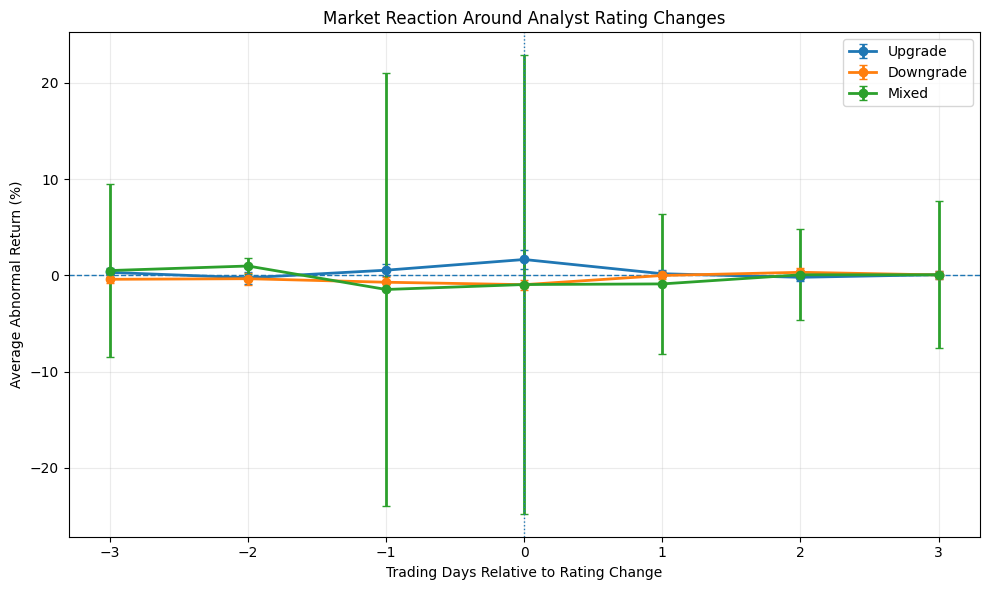

Event-study chart successfully generated.


,relative_day,mean,count,std,se,critical,ci_lower,ci_upper,event_type
0,-3,0.003142,62,0.019623,0.002492,1.999624,-0.001841,0.008126,Upgrade
1,-2,-0.002444,62,0.025563,0.003247,1.999624,-0.008936,0.004048,Upgrade
2,-1,0.005433,62,0.024544,0.003117,1.999624,-0.000800,0.011666,Upgrade
3,0,0.016531,62,0.039321,0.004994,1.999624,0.006546,0.026517,Upgrade
4,1,0.001731,62,0.013570,0.001723,1.999624,-0.001716,0.005177,Upgrade
5,2,-0.001963,61,0.015976,0.002046,2.000298,-0.006054,0.002129,Upgrade
6,3,0.000768,61,0.016206,0.002075,2.000298,-0.003382,0.004919,Upgrade
7,-3,-0.004036,57,0.016288,0.002157,2.003241,-0.008358,0.000286,Downgrade
8,-2,-0.003431,57,0.024244,0.003211,2.003241,-0.009864,0.003001,Downgrade
9,-1,-0.007096,57,0.021600,0.002861,2.003241,-0.012827,-0.001364,Downgrade



ANALYSIS COMPLETE

Generated files:
outputs/tables/earnings_comparison.csv (864 bytes)
outputs/tables/event_reaction_episodes.csv (11,945 bytes)
outputs/tables/event_study_results.csv (2,967 bytes)
outputs/tables/upgrade_downgrade_summary.csv (1,160 bytes)
outputs/figures/event_study.png (156,902 bytes)

Final episode counts:


,episodes,analyst_calls,average_CAR
event_type,,,
Downgrade,57,63,-0.016659
Mixed,2,4,-0.032938
Upgrade,62,68,0.023695


In [18]:

# ============================================================
# CELL 20: STATISTICAL ANALYSIS AND OUTPUT GENERATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Create output directories
OUTPUT_TABLES = Path("outputs/tables")
OUTPUT_FIGURES = Path("outputs/figures")

OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Consolidate simultaneous analyst calls
# ------------------------------------------------------------

analysis_events = events.loc[
    events["event_trade_date"].notna()
].copy()

def classify_episode(series):
    types = set(series.dropna())

    if len(types) == 1:
        return list(types)[0]

    return "Mixed"

def combine_earnings_overlap(series):
    values = series.dropna()

    if len(values) == 0:
        return pd.NA

    return bool(values.any())

episodes = (
    analysis_events
    .groupby(["ticker", "event_trade_date"])
    .agg(
        event_type=("event_type", classify_episode),
        earnings_overlap=(
            "earnings_overlap", combine_earnings_overlap
        ),
        n_rating_calls=("event_id", "nunique"),
        n_brokers=("broker", "nunique"),
        AR_0=("AR_0", "mean"),
        CAR_m1_p1=("CAR_m1_p1", "mean"),
        CAR_0_p1=("CAR_0_p1", "mean")
    )
    .reset_index()
)

episodes["earnings_overlap"] = (
    episodes["earnings_overlap"].astype("boolean")
)

print("Original analyst calls:", len(analysis_events))
print("Unique market-reaction episodes:", len(episodes))
print(
    "Simultaneous calls consolidated:",
    len(analysis_events) - len(episodes)
)

display(episodes.head(10))


# ------------------------------------------------------------
# 2. Calculate descriptive statistics and 95% CIs
# ------------------------------------------------------------

def summarize_returns(data, group_name, metric):

    values = pd.to_numeric(
        data[metric], errors="coerce"
    ).dropna()

    n = len(values)

    if n == 0:
        return {
            "group": group_name,
            "n": 0,
            "mean": np.nan,
            "median": np.nan,
            "std": np.nan,
            "ci_lower": np.nan,
            "ci_upper": np.nan
        }

    mean = values.mean()
    median = values.median()
    std = values.std(ddof=1) if n > 1 else np.nan

    if n > 1:
        se = std / np.sqrt(n)
        critical_value = stats.t.ppf(
            0.975, df=n - 1
        )

        ci_lower = mean - critical_value * se
        ci_upper = mean + critical_value * se

    else:
        ci_lower = np.nan
        ci_upper = np.nan

    return {
        "group": group_name,
        "n": n,
        "mean": mean,
        "median": median,
        "std": std,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    }


# ------------------------------------------------------------
# 3. Upgrade versus downgrade comparison
# ------------------------------------------------------------

type_results = []

for event_type in ["Upgrade", "Downgrade", "Mixed"]:

    subset = episodes.loc[
        episodes.event_type == event_type
    ]

    for metric in ["AR_0", "CAR_m1_p1", "CAR_0_p1"]:

        result = summarize_returns(
            subset,
            event_type,
            metric
        )

        result["metric"] = metric
        type_results.append(result)

type_summary = pd.DataFrame(type_results)

type_summary.to_csv(
    OUTPUT_TABLES / "upgrade_downgrade_summary.csv",
    index=False
)

print("\nUPGRADE VS DOWNGRADE RESULTS")

display(
    type_summary.pivot(
        index="group",
        columns="metric",
        values=["n", "mean", "ci_lower", "ci_upper"]
    )
)


# ------------------------------------------------------------
# 4. Earnings versus non-earnings comparison
# ------------------------------------------------------------

earnings_results = []

for overlap in [False, True]:

    subset = episodes.loc[
        episodes.earnings_overlap == overlap
    ]

    label = (
        "Earnings overlap"
        if overlap
        else "No earnings overlap"
    )

    for metric in ["AR_0", "CAR_m1_p1", "CAR_0_p1"]:

        result = summarize_returns(
            subset,
            label,
            metric
        )

        result["metric"] = metric
        earnings_results.append(result)

earnings_summary = pd.DataFrame(earnings_results)

earnings_summary.to_csv(
    OUTPUT_TABLES / "earnings_comparison.csv",
    index=False
)

print("\nEARNINGS COMPARISON")

display(
    earnings_summary.pivot(
        index="group",
        columns="metric",
        values=["n", "mean", "ci_lower", "ci_upper"]
    )
)



# ------------------------------------------------------------
# 5. Event-study plot: average abnormal returns
# ------------------------------------------------------------

# Consolidate simultaneous calls so each ticker/date/day
# contributes only one market-reaction observation.

episode_types = episodes[
    ["ticker", "event_trade_date", "event_type"]
].drop_duplicates()

plot_data = event_day_panel.drop_duplicates(
    subset=[
        "ticker",
        "event_trade_date",
        "relative_day"
    ]
).copy()

# Remove the original event_type before merging the
# consolidated episode classification.
plot_data = plot_data.drop(
    columns=["event_type"],
    errors="ignore"
)

plot_data = plot_data.merge(
    episode_types,
    on=["ticker", "event_trade_date"],
    how="left",
    validate="many_to_one"
)

plot_data = plot_data.dropna(
    subset=["abnormal_return", "event_type"]
)

plot_results = []

fig, ax = plt.subplots(figsize=(10, 6))

for event_type in ["Upgrade", "Downgrade", "Mixed"]:

    subset = plot_data.loc[
        plot_data["event_type"] == event_type
    ]

    if subset.empty:
        continue

    grouped = subset.groupby("relative_day")[
        "abnormal_return"
    ]

    stats_frame = grouped.agg(
        ["mean", "count", "std"]
    ).reset_index()

    stats_frame["se"] = (
        stats_frame["std"] /
        np.sqrt(stats_frame["count"])
    )

    stats_frame["critical"] = stats_frame["count"].apply(
        lambda n: stats.t.ppf(
            0.975, n - 1
        ) if n > 1 else np.nan
    )

    stats_frame["ci_lower"] = (
        stats_frame["mean"] -
        stats_frame["critical"] * stats_frame["se"]
    )

    stats_frame["ci_upper"] = (
        stats_frame["mean"] +
        stats_frame["critical"] * stats_frame["se"]
    )

    stats_frame["event_type"] = event_type

    plot_results.append(stats_frame)

    ax.errorbar(
        stats_frame["relative_day"],
        stats_frame["mean"] * 100,
        yerr=(
            stats_frame["ci_upper"] -
            stats_frame["mean"]
        ) * 100,
        marker="o",
        capsize=3,
        linewidth=2,
        label=event_type
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.axvline(0, linestyle=":", linewidth=1)

ax.set_title(
    "Market Reaction Around Analyst Rating Changes"
)

ax.set_xlabel("Trading Days Relative to Rating Change")
ax.set_ylabel("Average Abnormal Return (%)")

ax.set_xticks(range(-3, 4))
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    OUTPUT_FIGURES / "event_study.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

event_study_results = pd.concat(
    plot_results,
    ignore_index=True
)

event_study_results.to_csv(
    OUTPUT_TABLES / "event_study_results.csv",
    index=False
)

print("Event-study chart successfully generated.")
display(event_study_results)


# ------------------------------------------------------------
# 6. Save consolidated event-level dataset
# ------------------------------------------------------------

episodes.to_csv(
    OUTPUT_TABLES / "event_reaction_episodes.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Final output review
# ------------------------------------------------------------

print("\nANALYSIS COMPLETE")

print("\nGenerated files:")

for folder in [OUTPUT_TABLES, OUTPUT_FIGURES]:

    for file in sorted(folder.glob("*")):

        print(
            file,
            f"({file.stat().st_size:,} bytes)"
        )

print("\nFinal episode counts:")

display(
    episodes.groupby("event_type").agg(
        episodes=("ticker", "count"),
        analyst_calls=("n_rating_calls", "sum"),
        average_CAR=("CAR_m1_p1", "mean")
    )
)
